# Portada.
## Tarea 3: Análisis de datos reales chilenos
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
##### __Nombre:__ Matias Campos - Randall Vega
##### __Carrera:__ Ejecucion en informatica
##### __Asignatura:__ Mineria de Datos
##### __Fecha:__ 23 / 10 / 2025

# Introduccion.
――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――――
Este informe presenta un análisis de los datos de la pagina "eltiempo.es", datos los cuales fueron obtenidos mediante web scraping Utilizando distintas técnicas en base a las librerías como lo son requests y BeautifulSoup para extraer información relevante. Los datos extraidos se limpiaron y estructuraron en un DataFrame. Posterior a eso se analizan los patrones del clima mediante el clustering (K-Means), y predecir condiciones de nuevos dias o dias no registrados mediante KNN. Finalizando con la visualizacion y comparacion del metodo KNN y K-Means mediante grafico

## Parte 1: Web scrapping

- Para comenzar a analizar datos, primero tenemos que tener los datos, por lo que primero invetigamos paginas a las que se pueda web scrappear y terminamos encontrando la pagina "accuweather" esta página tiene la mayoria de datos necesarios, solo no contiene la humedad.

- Para empezar a extraer datos primero importamos las librerias que usaremos para ellos

In [1]:
import requests
from bs4 import BeautifulSoup
import time
import pandas as pd

- Ahora ingresamos la url de la página específica que scrappearemos, en este caso, la ciudad de chillán

In [2]:
url = "https://www.accuweather.com/es/cl/chillan/52615/daily-weather-forecast/52615"

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'
}
response = requests.get(url, headers=headers)
soup = BeautifulSoup(response.text, 'html.parser')

- Con esta estructura básica podemos extraer los datos que dispongamos de la página

In [3]:

clima_diario = soup.find_all('div', class_='daily-wrapper')
for clima in clima_diario:
    texto = clima.get_text(strip=True)


    fecha = clima.find('span', class_='sub').text.strip()
    max = clima.find('span', class_='high').text.strip()
    min = clima.find('span', class_='low').text.strip()
    estado = clima.find('div', class_='phrase').text.strip()
    
    nombre = texto.split("\n")[0] if "\n" in texto else texto
    valor = clima.find("span", class_="value").get_text(strip=True)
    if "Viento" in clima.text:
        viento = valor

    print(f"Fecha: {fecha}")
    print(f"Max: {max}")
    print(f"Min: {min}")
    print(f"Estado: {estado}")
    print(f"Viento: {viento}")

    data = {
        'Fecha': fecha,
        'Max': max,
        'Min': min,
        'Estado': estado,
        'Viento': viento
    }
    df = pd.DataFrame([data])
    df.to_csv('datos_clima.csv', mode='a', header=False, index=False)
    time.sleep(1)

Fecha: 29/10
Max: 26°
Min: /8°
Estado: Principalmente claro
Viento: 8°
Fecha: 30/10
Max: 26°
Min: /7°
Estado: Parcialmente soleado y agradable
Viento: 28°
Fecha: 31/10
Max: 22°
Min: /7°
Estado: Nuboso
Viento: 22°
Fecha: 1/11
Max: 25°
Min: /7°
Estado: Soleado y agradable
Viento: 26°
Fecha: 2/11
Max: 27°
Min: /10°
Estado: Intervalos de nubes y sol en la mañana, luego sol y algunas nubes en la tarde
Viento: 28°
Fecha: 3/11
Max: 26°
Min: /8°
Estado: Sol a través de algunas nubes altas
Viento: 25°
Fecha: 4/11
Max: 22°
Min: /9°
Estado: Nublado, con algunos chubascos
Viento: 21°
Fecha: 5/11
Max: 23°
Min: /7°
Estado: Nubes y sol
Viento: 26°
Fecha: 6/11
Max: 24°
Min: /7°
Estado: Principalmente nublado, con posibilidad de lluvia en la tarde
Viento: 24°
Fecha: 7/11
Max: 26°
Min: /7°
Estado: Parcialmente soleado
Viento: 29°
Fecha: 8/11
Max: 24°
Min: /10°
Estado: Principalmente soleado
Viento: 28°
Fecha: 9/11
Max: 24°
Min: /10°
Estado: Parcialmente soleado
Viento: 29°
Fecha: 10/11
Max: 24°
Min: /10

- Con esta estructura for podemos extraer la fecha, ubicada en un "span" con clase llamada "sub", esto se aplica tambien para la temperatura máxima, mínima y estado del clima.
Sin embargo, con el viento es distinto ya que este tiene el mismo nombre que varios otros "span" llamados "value", por lo que buscamos que el span contengo la palabra viento y extraemos solo ese dato. Asi pudiendo extraer los datos de solo los span que queremos.

## Parte 2: Limpieza y análisis de datos

- Cuando se extrayeron los datos, algunos de estos vienen con problemas de serie que tendremos que limpiar para poder utilizar los datos.

In [5]:
df = pd.read_csv('datos_clima.csv')
df["Max"] = df["Max"].str.replace("°", "", regex=False).astype(int)
df['Min'] = df['Min'].str.replace('°', '', regex=False)
df['Min'] = df['Min'].str.replace('/', '', regex=False).astype(int)
df['Viento'] = df['Viento'].str.replace('°', '', regex=False).astype(int)
print(df.head())

    Fecha  Max  Min                                             Estado  \
0  29-Oct   26    8                               Principalmente claro   
1  30-Oct   26    7                   Parcialmente soleado y agradable   
2  31-Oct   22    7                                             Nuboso   
3  01-Nov   25    7                                Soleado y agradable   
4  02-Nov   27   10  Intervalos de nubes y sol en la mañana, luego ...   

   Viento  Numero_Estado  
0       8            NaN  
1      28            NaN  
2      22            NaN  
3      26            NaN  
4      28            NaN  


- Este parte quita los simbolos de "°" de las temperaturas tanto maxima, como mínima y la velocidad del viento, ademas borra el simbolo "/" de la temperatura mínima, ya que de fabrica venia de esta forma: "/17°". Tambien con ".astype(int)" convertimos los valores que anteriormente no eran numericos, a este tipo de dato.

- Lo siguiente es normalizar los estados del clima, ya que la información entregada en la página es muy distinita entre si, por lo que le asignaremos un numero general a cada clima (soleado = 1, nublado = 2, lluvioso = 3)

In [7]:

df.loc[df["Estado"].isin([
    "Cantidad variable de nubes y sol",
    "Soleado y agradable",
    "Parcialmente soleado",
    "Parcialmente soleado y agradable",
    "Parcialmente soleado, más cálido y agradable",
    "Sol y áreas de nubosidad",
    "Nubes dando paso a algo de sol",
    "Soleado la mayor parte del día",
    "Soleado la mayor parte del tiempo",
    "Claro y soleado",
    "Sol y algunas nubes, con probabilidad de tormenta en la tarde",
    "Soleado",
    "Una buena cuota de sol",
    "Mucho sol",
    "Sol parcial",
    "Principalmente soleado",
    "Un día totalmente soleado",
    "Sol"
]), "Numero_Estado"] = 1

# Nublado = 2
df.loc[df["Estado"].isin([
    "Nublado y algo más fresco, con algunos chubascos",
    "Nubosidad variable",
    "Nubes y sol",
    "Nublado",
    "Bastante nublado",
    "Cantidad de nubes en aumento",
    "Parcial aparición de sol",
    "Incremento de nubosidad"
]), "Numero_Estado"] = 2

# Lluvia = 3
df.loc[df["Estado"].isin([
    "Principalmente nublado; posibilidad de algún chubasco en la mañana, luego posibilidad de lluvia en la tarde"
]), "Numero_Estado"] = 3
print(df.head())
df.to_csv('datos_clima.csv', index=False)

    Fecha  Max  Min                                             Estado  \
0  29-Oct   26    8                               Principalmente claro   
1  30-Oct   26    7                   Parcialmente soleado y agradable   
2  31-Oct   22    7                                             Nuboso   
3  01-Nov   25    7                                Soleado y agradable   
4  02-Nov   27   10  Intervalos de nubes y sol en la mañana, luego ...   

   Viento  Numero_Estado  
0       8            NaN  
1      28            1.0  
2      22            NaN  
3      26            1.0  
4      28            NaN  


- Con esto ya tenemos los datos limpios y preparados para trabajar en la cración de groaficos

- Pero primero haremos una descripicón breve con .describe()

In [8]:
print(df.describe())

             Max        Min     Viento  Numero_Estado
count  45.000000  45.000000  45.000000      28.000000
mean   24.155556  10.111111  26.511111       1.250000
std     1.870289   1.956600   4.143024       0.440959
min    21.000000   7.000000   8.000000       1.000000
25%    23.000000   9.000000  24.000000       1.000000
50%    24.000000  10.000000  27.000000       1.000000
75%    26.000000  12.000000  29.000000       1.250000
max    27.000000  13.000000  32.000000       2.000000


- Esta función nos muestra estadisticas de cada variable numerica en nuestro df, en este caso la cantidad de datos, valor promedio de estos, la desviación estandar, los cuartiles 1, 2 y 3 y los valores máximos y mínimos de cada columna

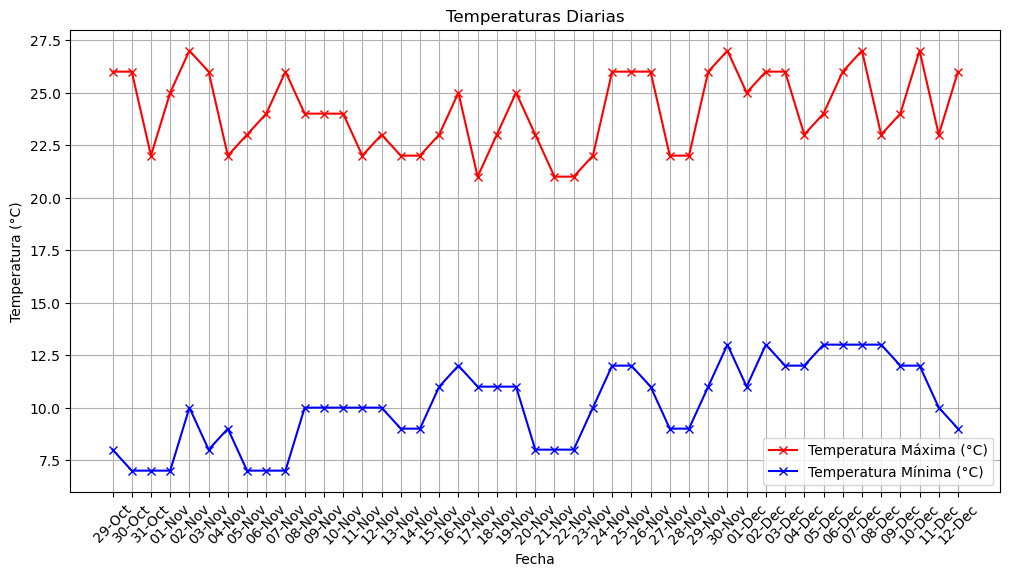

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
plt.plot(df['Fecha'], df['Max'], marker='x', label='Temperatura Máxima (°C)', color='r')
plt.plot(df['Fecha'], df['Min'], marker='x', label='Temperatura Mínima (°C)', color='b')
plt.title('Temperaturas Diarias')
plt.xticks(rotation=45)
plt.xlabel('Fecha')
plt.ylabel('Temperatura (°C)')
plt.legend()
plt.grid()
plt.show()

- Con matplotlib se creo un gráfico que muestra por fechas como cambian la temperatura mínima y máxima, mostrando una clara evolución positiva en la temperatura mínima, relacionada al verano ya que recien esta empezando, las temperaturas estan comenzado ha subir constantemente

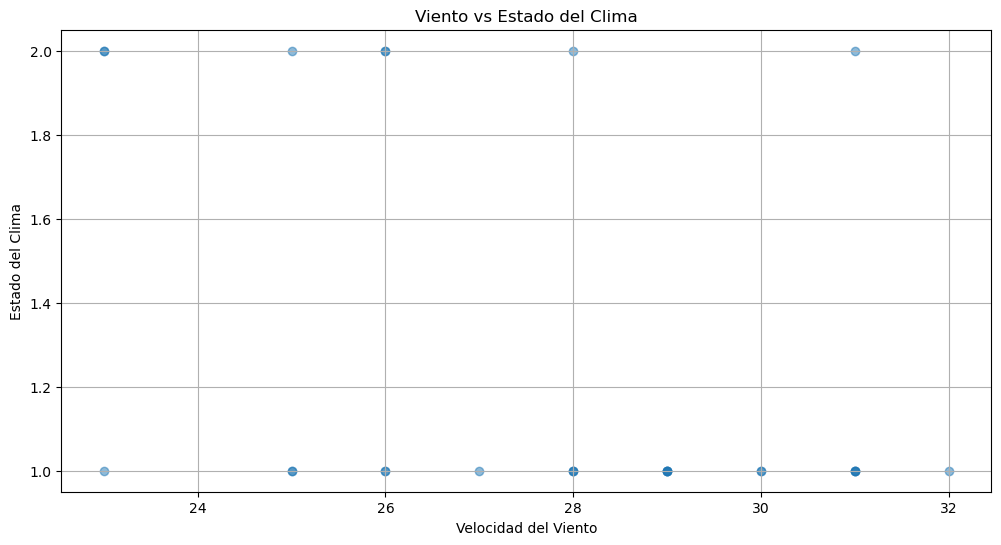

In [10]:
plt.figure(figsize=(12, 6))
plt.scatter(df['Viento'], df['Numero_Estado'], alpha=0.5)
plt.title('Viento vs Estado del Clima')
plt.xlabel('Velocidad del Viento')
plt.ylabel('Estado del Clima')
plt.grid(True)
plt.show()

# Paso 3 (K-Means)
### objetivo: Descubrir grupos de condiciones climaticas similares

 - Se importan las librerias que se utilizaran para poder trabajar con metodos de aproximacion

In [11]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

 - Se crea un nuevo DataFrame con las variables numericas, y liego escalar caracteristicas para mejorar KNN

In [12]:
df_nuevo = df[["Max", "Min", "Viento"]]

scaler = StandardScaler()
x_scaled = scaler.fit_transform(df_nuevo)

- Creamos la variable KMeans con k = 3

In [13]:
kmeans = KMeans (n_clusters = 3, random_state = 42)
kmeans.fit(x_scaled)

c:\Users\Matty\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=3, random_state=42)

 - Agregamos los resultados (etiquetas de cluster)

In [14]:
df["Cluster"] = kmeans.labels_

- Visualizamos los clusters en un graficos 

<function matplotlib.pyplot.show(close=None, block=None)>

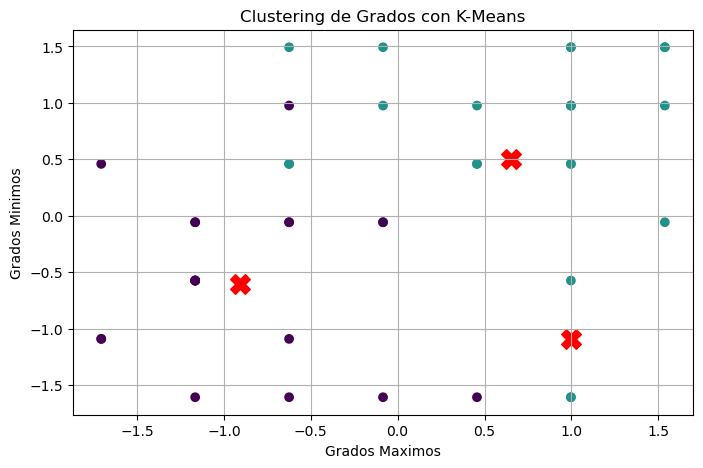

In [15]:
plt.figure(figsize = (8,5))
plt.scatter(x_scaled[:, 0], x_scaled[:, 1], c = df["Cluster"], cmap = "viridis")
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c = "red", s = 200, marker = "X")
plt.title("Clustering de Grados con K-Means")
plt.xlabel("Grados Maximos")
plt.ylabel("Grados Minimos")
plt.grid(True)
plt.show

# Paso 4 (KNN)
### objetivo: Predecir el tipo de dia a partir de nuevos datos 

In [16]:
x = df_nuevo[["Max", "Min"]]
y = df["Cluster"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state = 42)

- Dividir de nuevo el escalado

In [17]:
x_train_s, x_test_s, y_train_s, y_test_s = train_test_split(x, y, test_size = 0.3, random_state = 42)

- Creamos una variable KNN y entrenamos el modelo para regresion, usando nuestros datos como base 

In [18]:
knn = KNeighborsRegressor(n_neighbors = 3)
knn.fit(x_train, y_train)

KNeighborsRegressor(n_neighbors=3)

- Luego generamos las predicciones del modelo KNN sobre los datos, guardando los resultados en la variable y_pred

In [19]:
y_pred = knn.predict(x_test)

- Por ultimo visualizamos los datos de la precision del modelo KNN en comparacion con los valores reales predichos

<function matplotlib.pyplot.show(close=None, block=None)>

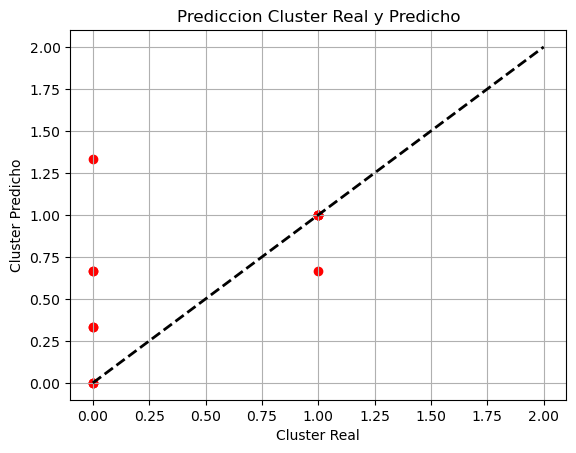

In [20]:
plt.scatter(y_test, y_pred, color = "red")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "k--", lw = 2)
plt.xlabel("Cluster Real")
plt.ylabel("Cluster Predicho")
plt.title("Prediccion Cluster Real y Predicho")
plt.grid(True)
plt.show

# Paso 5 (Comparacion y Reflexion)
### objetivo: Contrastar los dos enfoques (K-Means vs KNN) 

- Primero insertamos el grafico que se realizo con K-Means

<function matplotlib.pyplot.show(close=None, block=None)>

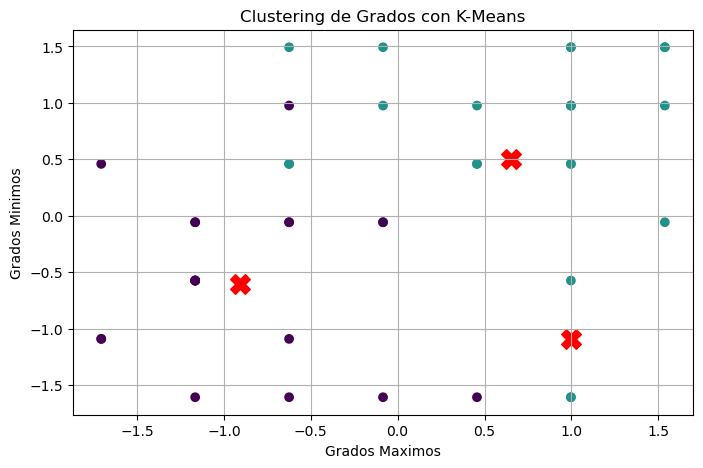

In [ ]:
# K-Means
plt.figure(figsize = (8,5))
plt.scatter(x_scaled[:, 0], x_scaled[:, 1], c = df["Cluster"], cmap = "viridis")
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c = "red", s = 200, marker = "X")
plt.title("Clustering de Grados con K-Means")
plt.xlabel("Grados Maximos")
plt.ylabel("Grados Minimos")
plt.grid(True)
plt.show

- Luego insertamos el grafico creado con KNN

<function matplotlib.pyplot.show(close=None, block=None)>

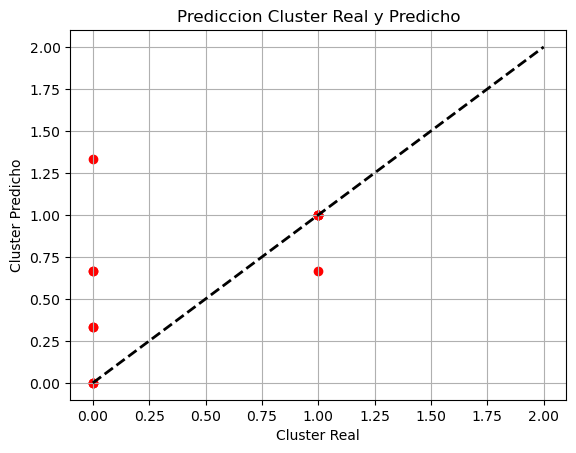

In [23]:
# KNN
plt.scatter(y_test, y_pred, color = "red")
plt.plot([y.min(), y.max()], [y.min(), y.max()], "k--", lw = 2)
plt.xlabel("Cluster Real")
plt.ylabel("Cluster Predicho")
plt.title("Prediccion Cluster Real y Predicho")
plt.grid(True)
plt.show

### ¿Que metodo agrupa mejor los dias con condiciones similares?
##### Segun los graficos, el mejor metodo seria el metodo K-Means, ya que agrupa los dias con condiciones similares

### ¿Que metodo usarias si tuvieras datos futuros con etiquetas conocidas?
##### Usaria KNN, ya que KNN va aprendiendo en base a los ejemplos dados en las etiquetas conocidas, lo que le hace mas facil predecir valores futuros

### ¿Que aprendiste sobre la diferencia entre clustering y clasificacion supervisada?
##### Una de las principales diferencias es que K-Means agrupa por datos, o grupos, y KNN va aprendiendo en base a las etiquetas conocidas 